# Restaurant Pricing Intelligence & Promotion Optimizer
## Notebook 1 — Exploratory Data Analysis

This project builds a decision-support tool for a multi-outlet restaurant brand: it predicts how many
plates of a menu item will sell, tests different menu prices and offers, and recommends the most
profitable combination.

**Dataset.** A synthetic dataset of daily sales for 30 menu items across 8 outlets over two years
(`src/generate_restaurant_data.py` creates it). One row = one menu item, at one outlet, on one day.
It records the price charged, any offer running, the competitor's price, footfall, weather, festivals,
units sold and costs.

This notebook answers: *what drives demand, and does more demand always mean more profit?*

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
df = pd.read_csv("../data/synthetic_restaurant_sales_data.csv")
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (175200, 33)


In [3]:
df.head()

,Date,Day_of_Week,Is_Weekend,Season,Holiday_Flag,Festival,Item_ID,Item_Name,Category,Food_Type,Outlet_ID,City,Outlet_Type,Location_Type,Footfall_Index,Base_Price,Selling_Price,Discount_Percentage,Promotion_Flag,Promotion_Type,Promotion_Depth,Promotion_Cost,Competitor_Price,Competitor_Promotion_Flag,Competitor_Discount,Temperature,Rainfall,Units_Sold,Unit_Cost,Overhead_Cost,Total_Cost,Revenue,Profit
0,2024-10-01,Tuesday,0,Post-Monsoon,0,No Festival,M01,Paneer Tikka,Starters,Veg,R01,Delhi,Casual Dining,High Street,0.89,300,300,0,0,No Promotion,0.0,0.0,280,0,0.0,27.4,0.0,38,92.17,2872.32,6374.78,11400.0,5025.22
1,2024-10-01,Tuesday,0,Post-Monsoon,0,No Festival,M02,Chicken Tikka,Starters,Non-Veg,R01,Delhi,Casual Dining,High Street,0.89,340,323,0,0,No Promotion,0.0,0.0,337,0,0.0,27.4,0.0,34,116.18,3565.96,7516.08,10982.0,3465.92
2,2024-10-01,Tuesday,0,Post-Monsoon,0,No Festival,M03,Veg Spring Rolls,Starters,Veg,R01,Delhi,Casual Dining,High Street,0.89,225,202,0,0,No Promotion,0.0,0.0,243,0,0.0,27.4,0.0,24,60.73,1879.11,3336.63,4848.0,1511.37
3,2024-10-01,Tuesday,0,Post-Monsoon,0,No Festival,M04,Honey Chilli Potato,Starters,Veg,R01,Delhi,Casual Dining,High Street,0.89,235,258,0,0,No Promotion,0.0,0.0,247,0,0.0,27.4,0.0,23,56.82,2123.97,3430.83,5934.0,2503.17
4,2024-10-01,Tuesday,0,Post-Monsoon,0,No Festival,M05,Tandoori Chicken,Starters,Non-Veg,R01,Delhi,Casual Dining,High Street,0.89,360,378,0,0,No Promotion,0.0,0.0,381,0,0.0,27.4,0.0,24,134.66,3215.11,6446.95,9072.0,2625.05


## 1. Dataset overview

In [4]:
print(f"Number of observations : {df.shape[0]:,}")
print(f"Number of variables    : {df.shape[1]}")
print(f"Date range             : {df['Date'].min().date()} to {df['Date'].max().date()} ({df['Date'].nunique()} days)")
print(f"Menu items             : {df['Item_ID'].nunique()}")
print(f"Outlets                : {df['Outlet_ID'].nunique()}")
print(f"Menu categories        : {sorted(df['Category'].unique())}")

Number of observations : 175,200
Number of variables    : 33
Date range             : 2024-10-01 to 2026-09-30 (730 days)
Menu items             : 30
Outlets                : 8
Menu categories        : ['Beverages', 'Breads', 'Desserts', 'Main Course', 'Rice & Biryani', 'Starters']


In [5]:
df[["Outlet_ID", "City", "Outlet_Type", "Location_Type"]].drop_duplicates().reset_index(drop=True)

,Outlet_ID,City,Outlet_Type,Location_Type
0,R01,Delhi,Casual Dining,High Street
1,R02,Delhi,Quick Service,Mall
2,R03,Chandigarh,Casual Dining,Mall
3,R04,Mumbai,Casual Dining,High Street
4,R05,Mumbai,Cloud Kitchen,Residential
5,R06,Bengaluru,Cafe,Office Hub
6,R07,Hyderabad,Quick Service,Office Hub
7,R08,Pune,Cafe,High Street


In [6]:
menu = (
    df.groupby(["Item_ID", "Item_Name", "Category", "Food_Type"])
    .agg(Avg_Base_Price=("Base_Price", "mean"), Avg_Food_Cost=("Unit_Cost", "mean"), Avg_Daily_Units=("Units_Sold", "mean"))
    .round(1)
    .reset_index()
)
menu["Food_Cost_%"] = (menu["Avg_Food_Cost"] / menu["Avg_Base_Price"] * 100).round(1)
menu

,Item_ID,Item_Name,Category,Food_Type,Avg_Base_Price,Avg_Food_Cost,Avg_Daily_Units,Food_Cost_%
0,M01,Paneer Tikka,Starters,Veg,286.9,88.9,28.5,31.0
1,M02,Chicken Tikka,Starters,Non-Veg,327.5,111.3,28.1,34.0
2,M03,Veg Spring Rolls,Starters,Veg,216.9,58.6,19.5,27.0
3,M04,Honey Chilli Potato,Starters,Veg,226.2,54.3,23.7,24.0
4,M05,Tandoori Chicken,Starters,Non-Veg,346.9,128.3,22.3,37.0
5,M06,Butter Chicken,Main Course,Non-Veg,398.1,139.3,39.6,35.0
6,M07,Dal Makhani,Main Course,Veg,296.9,71.2,34.2,24.0
7,M08,Paneer Butter Masala,Main Course,Veg,337.5,108.0,31.8,32.0
8,M09,Kadhai Chicken,Main Course,Non-Veg,388.1,139.8,20.5,36.0
9,M10,Mixed Veg Curry,Main Course,Veg,256.9,66.8,15.8,26.0


## 2. Data quality

In [7]:
quality = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique(),
})
quality

,Data Type,Missing Values,Missing %,Unique Values
Date,datetime64[ns],0,0.0,730
Day_of_Week,object,0,0.0,7
Is_Weekend,int64,0,0.0,2
Season,object,0,0.0,4
Holiday_Flag,int64,0,0.0,2
Festival,object,0,0.0,11
Item_ID,object,0,0.0,30
Item_Name,object,0,0.0,30
Category,object,0,0.0,6
Food_Type,object,0,0.0,2


In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Rows per item-outlet pair:", df.groupby(["Item_ID", "Outlet_ID"]).size().unique())
print("Negative units:", (df["Units_Sold"] < 0).sum(), "| Zero-unit days:", (df["Units_Sold"] == 0).sum())

Duplicate rows: 0
Rows per item-outlet pair: [730]
Negative units: 0 | Zero-unit days: 45


## 3. Descriptive statistics

In [9]:
df.select_dtypes(include=np.number).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Is_Weekend,175200.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
Holiday_Flag,175200.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
Footfall_Index,175200.0,1.00,0.22,0.43,0.83,0.97,1.15,2.03
Base_Price,175200.0,209.88,113.29,30.00,118.75,197.50,301.25,500.00
Selling_Price,175200.0,203.16,111.43,22.00,113.00,184.00,290.00,550.00
Discount_Percentage,175200.0,2.68,5.64,0.00,0.00,0.00,0.00,20.00
Promotion_Flag,175200.0,0.32,0.47,0.00,0.00,0.00,1.00,1.00
Promotion_Depth,175200.0,0.06,0.12,0.00,0.00,0.00,0.10,0.50
Promotion_Cost,175200.0,131.32,693.40,0.00,0.00,0.00,0.00,19317.48
Competitor_Price,175200.0,207.08,112.96,21.00,114.00,188.00,299.00,521.00


In [10]:
for col in ["Promotion_Type", "Festival", "Season", "Day_of_Week"]:
    print(f"\n{col}")
    print(df[col].value_counts())


Promotion_Type
Promotion_Type
No Promotion       119653
10% Discount        12108
15% Discount        10321
Combo Offer          8896
Buy One Get One      8841
20% Discount         7738
5% Discount          7643
Name: count, dtype: int64

Festival
Festival
No Festival         166080
Diwali                2400
Dussehra               960
Christmas              960
New Year               960
Eid                    960
Holi                   960
Valentines Day         480
Republic Day           480
Raksha Bandhan         480
Independence Day       480
Name: count, dtype: int64

Season
Season
Summer          58560
Monsoon         44160
Winter          43200
Post-Monsoon    29280
Name: count, dtype: int64

Day_of_Week
Day_of_Week
Tuesday      25200
Wednesday    25200
Thursday     24960
Friday       24960
Saturday     24960
Sunday       24960
Monday       24960
Name: count, dtype: int64


## 4. Demand over time

**Business question:** how does demand move across the two years?

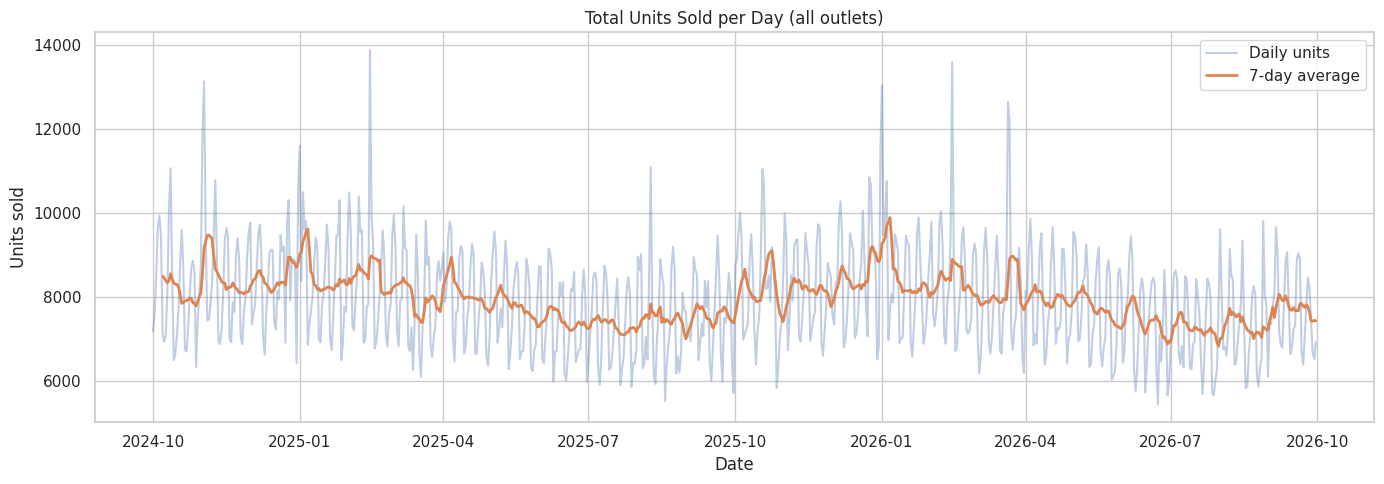

In [11]:
daily = df.groupby("Date")["Units_Sold"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, alpha=0.35, label="Daily units")
plt.plot(daily.index, daily.rolling(7).mean(), linewidth=2, label="7-day average")
plt.title("Total Units Sold per Day (all outlets)")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Day-of-week pattern

**Business question:** which days are busy, and is that the same for every location?

To compare items that sell very different volumes, demand is expressed relative to each item's own
average at its outlet (1.0 = a normal day for that item).

In [12]:
df["Relative_Demand"] = df["Units_Sold"] / df.groupby(["Item_ID", "Outlet_ID"])["Units_Sold"].transform("mean")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = (
    df.groupby(["Location_Type", "Day_of_Week"])["Relative_Demand"].mean()
    .unstack("Day_of_Week")[day_order]
    .round(2)
)
dow

Day_of_Week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Location_Type,,,,,,,
High Street,0.80,0.82,0.90,0.97,1.15,1.23,1.14
Mall,0.72,0.73,0.84,0.89,1.17,1.36,1.29
Office Hub,1.06,1.04,1.12,1.11,1.06,0.84,0.78
Residential,0.87,0.85,0.92,0.97,1.11,1.16,1.12


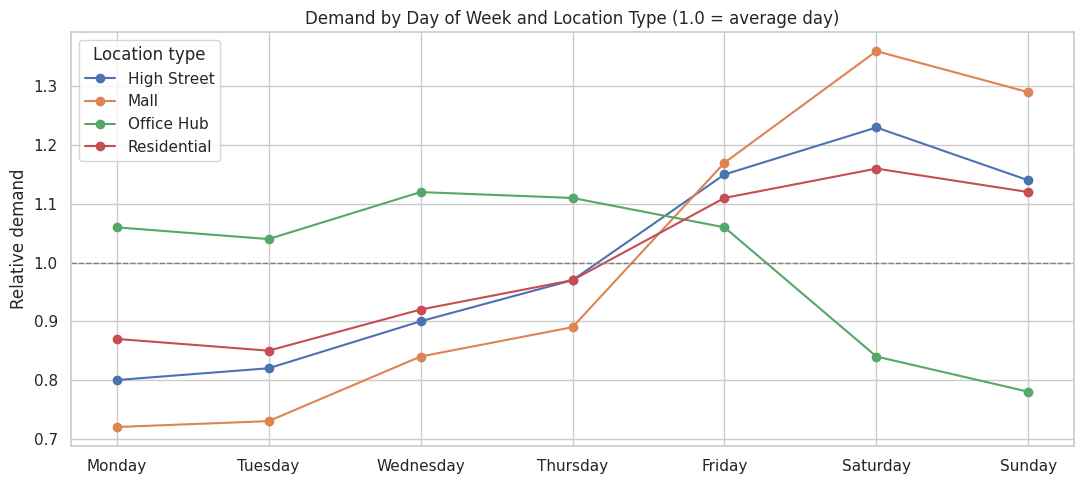

In [13]:
plt.figure(figsize=(11, 5))
for location in dow.index:
    plt.plot(day_order, dow.loc[location], marker="o", label=location)
plt.axhline(1.0, color="grey", linestyle="--", linewidth=1)
plt.title("Demand by Day of Week and Location Type (1.0 = average day)")
plt.ylabel("Relative demand")
plt.legend(title="Location type")
plt.tight_layout()
plt.show()

## 6. Price and demand

**Business question:** when the menu price moves, how much does demand move?

Only days without an offer are used here, so the effect of price is not mixed with the effect of promotions.

In [14]:
no_promo = df[df["Promotion_Flag"] == 0].copy()
no_promo["Price_Index"] = no_promo["Selling_Price"] / no_promo["Base_Price"]
no_promo["Price_Level"] = (no_promo["Price_Index"] / 0.05).round() * 0.05

price_curve = no_promo.groupby("Price_Level")["Relative_Demand"].agg(["mean", "count"]).round(3)
price_curve

,mean,count
Price_Level,,
0.90,1.045,17264
0.95,0.977,24030
1.00,0.914,37509
1.05,0.855,24197
1.10,0.799,16653


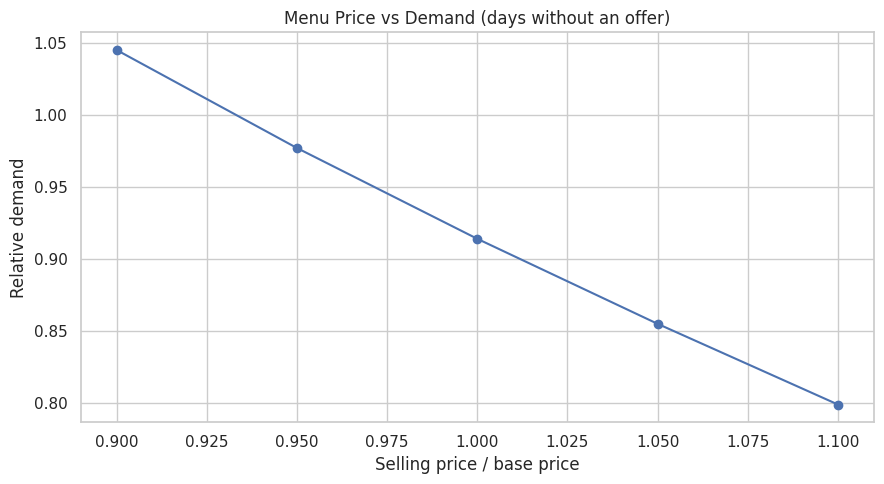

Estimated price elasticity of demand: -1.39
(a 1% higher price goes with roughly a 1.4% drop in units sold)


In [15]:
plt.figure(figsize=(9, 5))
plt.plot(price_curve.index, price_curve["mean"], marker="o")
plt.title("Menu Price vs Demand (days without an offer)")
plt.xlabel("Selling price / base price")
plt.ylabel("Relative demand")
plt.tight_layout()
plt.show()

valid = no_promo[no_promo["Units_Sold"] > 0]
elasticity = np.polyfit(np.log(valid["Price_Index"]), np.log(valid["Relative_Demand"]), 1)[0]
print(f"Estimated price elasticity of demand: {elasticity:.2f}")
print("(a 1% higher price goes with roughly a", f"{abs(elasticity):.1f}% drop in units sold)")

In [16]:
by_category = {}
for category, part in valid.groupby("Category"):
    by_category[category] = np.polyfit(np.log(part["Price_Index"]), np.log(part["Relative_Demand"]), 1)[0]
pd.Series(by_category, name="Price elasticity").round(2).sort_values()

Rice & Biryani   -1.54
Desserts         -1.47
Starters         -1.43
Beverages        -1.38
Main Course      -1.34
Breads           -1.12
Name: Price elasticity, dtype: float64

## 7. Promotion effectiveness

**Business question:** which offers lift demand the most?

In [17]:
base_level = df.loc[df["Promotion_Type"] == "No Promotion", "Relative_Demand"].mean()

promo = df.groupby("Promotion_Type").agg(
    Days=("Units_Sold", "size"),
    Avg_Units=("Units_Sold", "mean"),
    Relative_Demand=("Relative_Demand", "mean"),
)
promo["Demand_Lift_%"] = (promo["Relative_Demand"] / base_level - 1) * 100
promo = promo.sort_values("Demand_Lift_%", ascending=False).round(2)
promo

,Days,Avg_Units,Relative_Demand,Demand_Lift_%
Promotion_Type,,,,
20% Discount,7738,44.33,1.31,42.90
15% Discount,10321,40.51,1.22,33.06
Buy One Get One,8841,39.47,1.21,32.02
Combo Offer,8896,37.55,1.16,26.91
10% Discount,12108,36.93,1.13,22.68
5% Discount,7643,35.66,1.04,13.12
No Promotion,119653,30.41,0.92,0.00


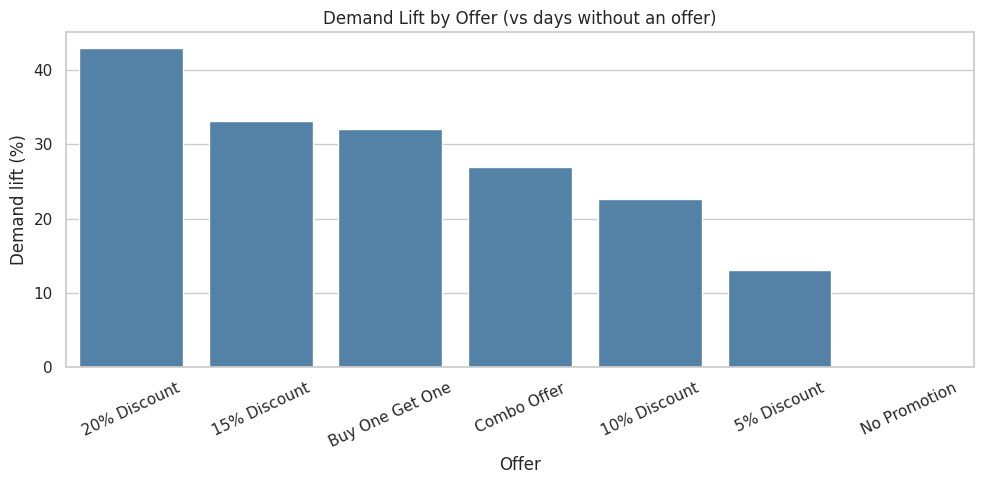

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(x=promo.index, y=promo["Demand_Lift_%"], color="steelblue")
plt.title("Demand Lift by Offer (vs days without an offer)")
plt.xlabel("Offer")
plt.ylabel("Demand lift (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Do offers work equally well every day?

In [19]:
df["Day_Type"] = np.where(df["Holiday_Flag"] == 1, "Festival", np.where(df["Is_Weekend"] == 1, "Weekend", "Weekday"))

lift_by_day = df.groupby(["Promotion_Type", "Day_Type"])["Relative_Demand"].mean().unstack("Day_Type")
lift_by_day = ((lift_by_day / lift_by_day.loc["No Promotion"] - 1) * 100).round(1)
lift_by_day = lift_by_day.drop(index="No Promotion")[["Weekday", "Weekend", "Festival"]]
lift_by_day

Day_Type,Weekday,Weekend,Festival
Promotion_Type,,,
10% Discount,26.5,14.2,14.2
15% Discount,38.3,22.4,24.3
20% Discount,48.9,30.8,31.6
5% Discount,15.5,7.4,5.8
Buy One Get One,46.7,7.6,8.7
Combo Offer,32.9,15.2,14.0


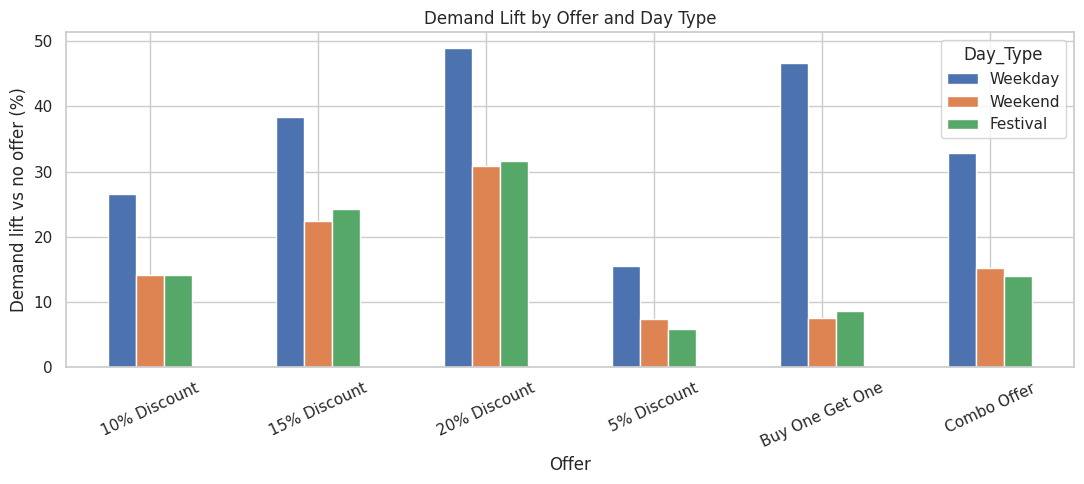

In [20]:
lift_by_day.plot(kind="bar", figsize=(11, 5))
plt.title("Demand Lift by Offer and Day Type")
plt.ylabel("Demand lift vs no offer (%)")
plt.xlabel("Offer")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Which offer suits which category? (weekdays)

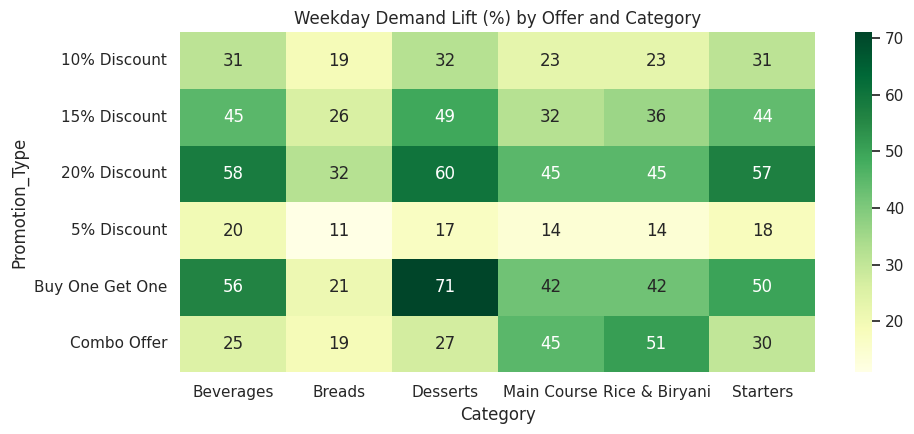

In [21]:
weekday = df[df["Day_Type"] == "Weekday"]
lift_by_cat = weekday.groupby(["Promotion_Type", "Category"])["Relative_Demand"].mean().unstack("Category")
lift_by_cat = ((lift_by_cat / lift_by_cat.loc["No Promotion"] - 1) * 100).round(0).drop(index="No Promotion")

plt.figure(figsize=(10, 4.5))
sns.heatmap(lift_by_cat, annot=True, fmt=".0f", cmap="YlGn")
plt.title("Weekday Demand Lift (%) by Offer and Category")
plt.tight_layout()
plt.show()

## 8. Competitor pricing

**Business question:** do we lose orders when the competitor runs an offer?

In [22]:
comp = df.groupby("Competitor_Promotion_Flag")["Relative_Demand"].mean()
print(comp.round(3))
print(f"\nWhen the competitor runs an offer, our demand is {(1 - comp[1] / comp[0]) * 100:.1f}% lower.")

by_discount = df.groupby("Competitor_Discount")["Relative_Demand"].mean().round(3)
by_discount

Competitor_Promotion_Flag
0    1.007
1    0.925
Name: Relative_Demand, dtype: float64

When the competitor runs an offer, our demand is 8.2% lower.


Competitor_Discount
0.00    1.007
0.10    0.969
0.15    0.931
0.20    0.901
0.25    0.898
Name: Relative_Demand, dtype: float64

## 9. Festivals

**Business question:** which festivals bring guests in?

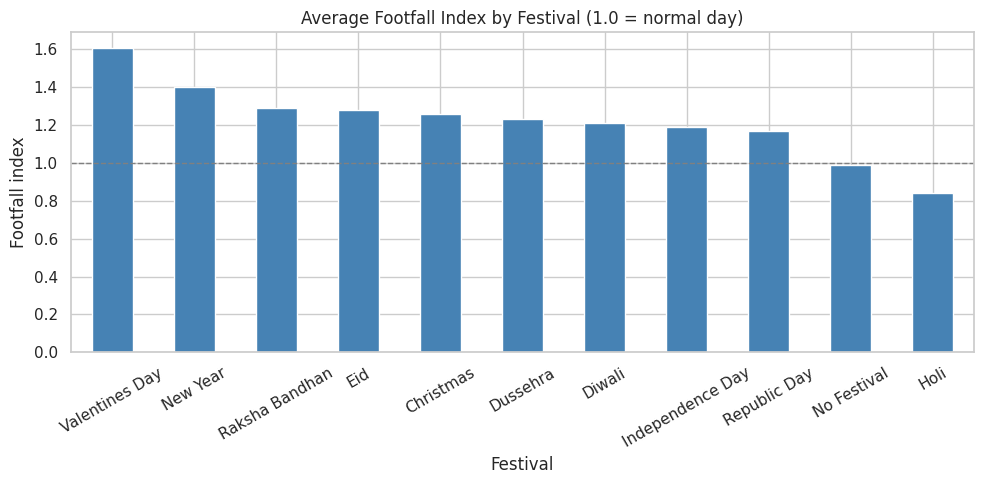

Festival
Valentines Day      1.61
New Year            1.40
Raksha Bandhan      1.29
Eid                 1.28
Christmas           1.26
Dussehra            1.23
Diwali              1.21
Independence Day    1.19
Republic Day        1.17
No Festival         0.99
Holi                0.84
Name: Footfall_Index, dtype: float64

In [23]:
outlet_day = df.drop_duplicates(["Date", "Outlet_ID"])
festival = outlet_day.groupby("Festival")["Footfall_Index"].mean().sort_values(ascending=False).round(2)

plt.figure(figsize=(10, 5))
festival.plot(kind="bar", color="steelblue")
plt.axhline(1.0, color="grey", linestyle="--", linewidth=1)
plt.title("Average Footfall Index by Festival (1.0 = normal day)")
plt.ylabel("Footfall index")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
festival

## 10. Weather

**Business question:** how do temperature and rain change what guests order?

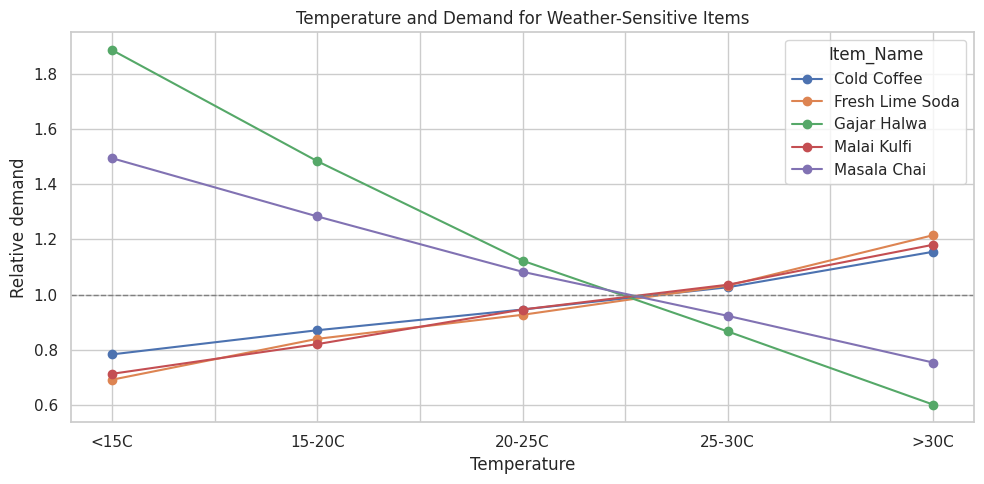

In [24]:
df["Temp_Band"] = pd.cut(df["Temperature"], [0, 15, 20, 25, 30, 45], labels=["<15C", "15-20C", "20-25C", "25-30C", ">30C"])
items = ["Fresh Lime Soda", "Cold Coffee", "Malai Kulfi", "Masala Chai", "Gajar Halwa"]
temp = df[df["Item_Name"].isin(items)].groupby(["Temp_Band", "Item_Name"])["Relative_Demand"].mean().unstack("Item_Name")

temp.plot(marker="o", figsize=(10, 5))
plt.axhline(1.0, color="grey", linestyle="--", linewidth=1)
plt.title("Temperature and Demand for Weather-Sensitive Items")
plt.ylabel("Relative demand")
plt.xlabel("Temperature")
plt.tight_layout()
plt.show()

In [25]:
outlet_day = df.drop_duplicates(["Date", "Outlet_ID"]).copy()
outlet_day["Rain"] = np.where(outlet_day["Rainfall"] >= 10, "Heavy rain (10mm+)", np.where(outlet_day["Rainfall"] > 0, "Light rain", "Dry"))
outlet_day["Normal_Footfall"] = outlet_day.groupby(["Outlet_ID", "Day_of_Week"])["Footfall_Index"].transform("mean")
outlet_day["Footfall_vs_Normal"] = outlet_day["Footfall_Index"] / outlet_day["Normal_Footfall"]
rain = outlet_day.groupby(["Outlet_Type", "Rain"])["Footfall_vs_Normal"].mean().unstack("Rain").round(2)
rain[["Dry", "Light rain", "Heavy rain (10mm+)"]]

Rain,Dry,Light rain,Heavy rain (10mm+)
Outlet_Type,,,
Cafe,1.04,0.95,0.80
Casual Dining,1.04,0.94,0.77
Cloud Kitchen,0.97,0.98,1.12
Quick Service,1.03,0.95,0.79


## 11. Profitability

**Business question:** does the offer that sells the most also earn the most?

In [26]:
promo_profit = df.groupby("Promotion_Type").agg(
    Avg_Units=("Units_Sold", "mean"),
    Avg_Revenue=("Revenue", "mean"),
    Avg_Profit=("Profit", "mean"),
    Revenue=("Revenue", "sum"),
    Profit=("Profit", "sum"),
)
promo_profit["Profit_Margin_%"] = promo_profit["Profit"] / promo_profit["Revenue"] * 100
promo_profit = promo_profit.drop(columns=["Revenue", "Profit"]).sort_values("Avg_Units", ascending=False).round(1)
promo_profit

,Avg_Units,Avg_Revenue,Avg_Profit,Profit_Margin_%
Promotion_Type,,,,
20% Discount,44.3,6203.3,2285.7,36.8
15% Discount,40.5,6358.3,2412.6,37.9
Buy One Get One,39.5,7321.3,1249.1,17.1
Combo Offer,37.5,6239.4,2132.4,34.2
10% Discount,36.9,5954.7,2367.8,39.8
5% Discount,35.7,5835.2,2372.4,40.7
No Promotion,30.4,5480.7,2184.9,39.9


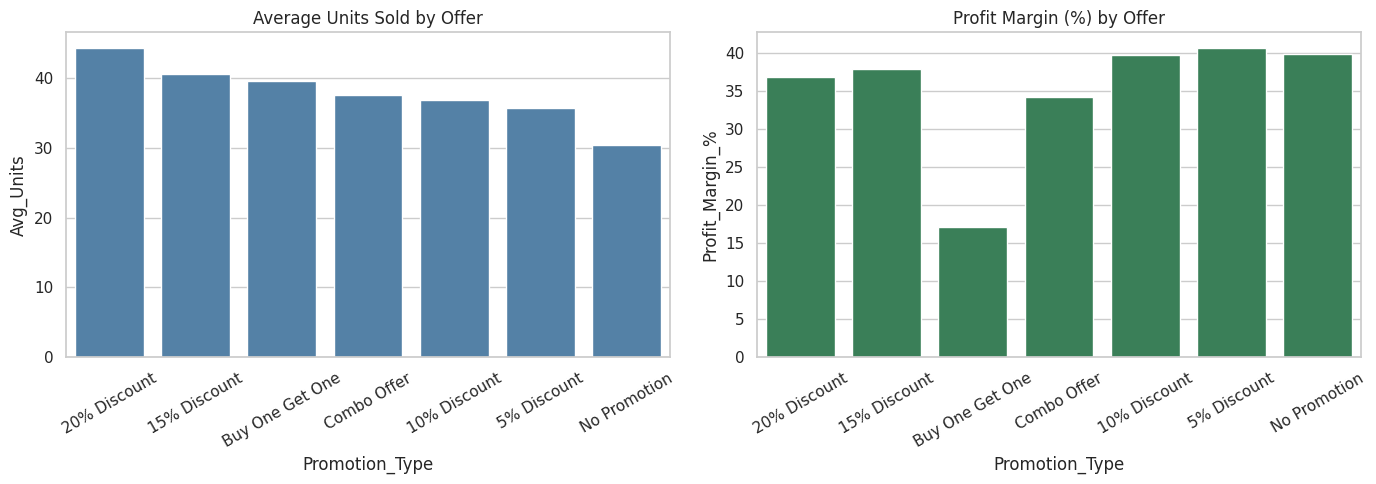

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = promo_profit.index
sns.barplot(x=order, y=promo_profit["Avg_Units"], ax=axes[0], color="steelblue")
axes[0].set_title("Average Units Sold by Offer")
axes[0].tick_params(axis="x", rotation=30)
sns.barplot(x=order, y=promo_profit["Profit_Margin_%"], ax=axes[1], color="seagreen")
axes[1].set_title("Profit Margin (%) by Offer")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [28]:
category = df.groupby("Category").agg(
    Units_Sold=("Units_Sold", "sum"), Revenue=("Revenue", "sum"), Profit=("Profit", "sum"), Avg_Price=("Selling_Price", "mean")
)
category["Profit_Margin_%"] = category["Profit"] / category["Revenue"] * 100
category.sort_values("Profit", ascending=False).round(1)

,Units_Sold,Revenue,Profit,Avg_Price,Profit_Margin_%
Category,,,,,
Main Course,829012,274484893.0,96749650.4,325.0,35.2
Starters,713094,194812353.0,68953365.0,271.5,35.4
Rice & Biryani,767029,211344437.0,68932053.9,282.0,32.6
Beverages,1135322,121542310.0,57975696.3,117.9,47.7
Breads,1753422,114973429.0,53177516.8,74.8,46.3
Desserts,604965,89186758.0,35044178.2,147.8,39.3


## 12. Correlation analysis

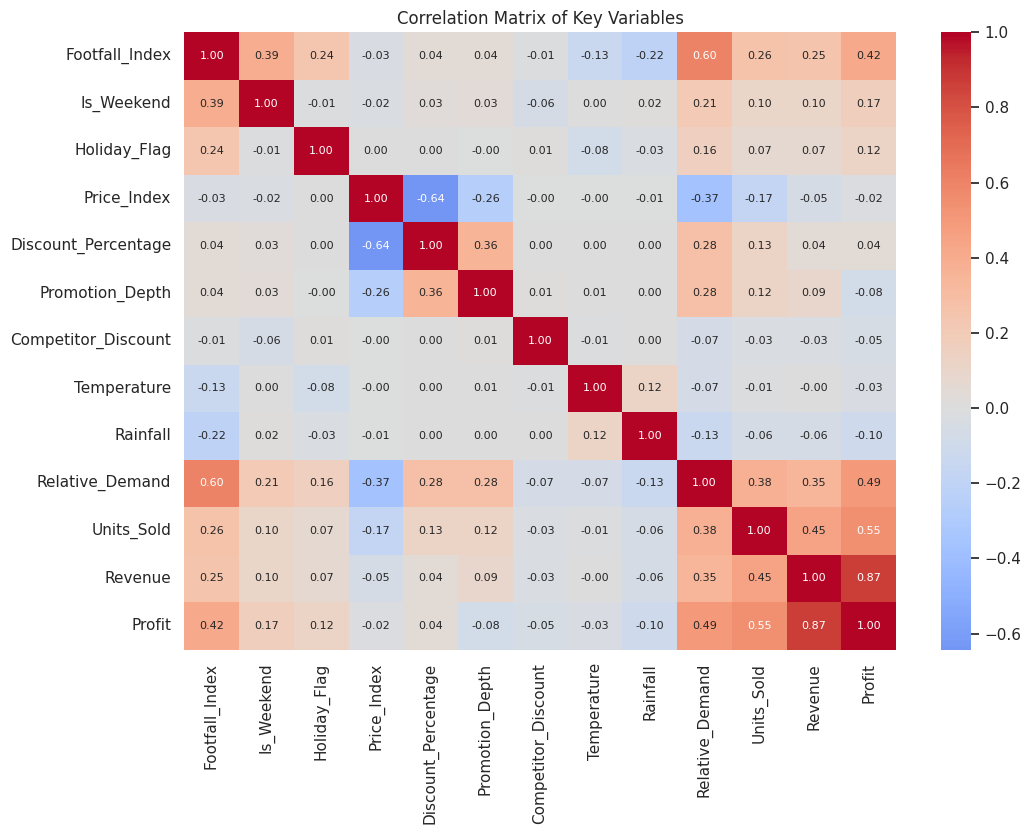

In [29]:
df["Price_Index"] = df["Selling_Price"] / df["Base_Price"]
corr_cols = [
    "Footfall_Index", "Is_Weekend", "Holiday_Flag", "Price_Index", "Discount_Percentage",
    "Promotion_Depth", "Competitor_Discount", "Temperature", "Rainfall",
    "Relative_Demand", "Units_Sold", "Revenue", "Profit",
]
plt.figure(figsize=(11, 8.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation Matrix of Key Variables")
plt.tight_layout()
plt.show()

## 13. Key business insights

The figures below are calculated from the data in this notebook.

In [30]:
weekend_lift = dow[["Saturday", "Sunday"]].mean(axis=1) / dow[["Monday", "Tuesday", "Wednesday", "Thursday"]].mean(axis=1) - 1
top_offer = promo["Demand_Lift_%"].idxmax()
best_margin = promo_profit["Profit_Margin_%"].idxmax()
worst_margin = promo_profit["Profit_Margin_%"].idxmin()

print(f"1. Location decides the busy days. Weekend vs weekday demand: "
      + ", ".join(f"{loc} {val:+.0%}" for loc, val in weekend_lift.items()) + ".")
print(f"2. Demand is price sensitive: elasticity is about {elasticity:.2f}, "
      f"strongest for {min(by_category, key=by_category.get)} and weakest for {max(by_category, key=by_category.get)}.")
print(f"3. {top_offer} gives the biggest demand lift ({promo.loc[top_offer, 'Demand_Lift_%']:.0f}%) but a lower profit margin "
      f"than no offer ({promo_profit.loc[top_offer, 'Profit_Margin_%']:.0f}% vs {promo_profit.loc['No Promotion', 'Profit_Margin_%']:.0f}%). "
      f"{worst_margin} has the lowest margin of all ({promo_profit.loc[worst_margin, 'Profit_Margin_%']:.0f}%).")
print(f"4. Offers work on slow days. Average lift across offers: weekday {lift_by_day['Weekday'].mean():.0f}%, "
      f"weekend {lift_by_day['Weekend'].mean():.0f}%, festival {lift_by_day['Festival'].mean():.0f}%.")
print(f"5. Offers suit different categories: Combo Offer lifts Main Course by {lift_by_cat.loc['Combo Offer', 'Main Course']:.0f}% "
      f"but Breads by only {lift_by_cat.loc['Combo Offer', 'Breads']:.0f}%; "
      f"Buy One Get One lifts Desserts by {lift_by_cat.loc['Buy One Get One', 'Desserts']:.0f}%.")
print(f"6. A competitor offer costs us about {(1 - comp[1] / comp[0]) * 100:.0f}% of demand.")
print(f"7. Festivals are not all good for business: {festival.index[0]} has the highest footfall ({festival.iloc[0]:.2f}x), "
      f"{festival.index[-1]} the lowest ({festival.iloc[-1]:.2f}x).")
print("8. Higher demand is not higher profit - which is why the optimiser in Notebook 4 maximises expected profit, not units sold.")

1. Location decides the busy days. Weekend vs weekday demand: High Street +36%, Mall +67%, Office Hub -25%, Residential +26%.
2. Demand is price sensitive: elasticity is about -1.39, strongest for Rice & Biryani and weakest for Breads.
3. 20% Discount gives the biggest demand lift (43%) but a lower profit margin than no offer (37% vs 40%). Buy One Get One has the lowest margin of all (17%).
4. Offers work on slow days. Average lift across offers: weekday 35%, weekend 16%, festival 16%.
5. Offers suit different categories: Combo Offer lifts Main Course by 45% but Breads by only 19%; Buy One Get One lifts Desserts by 71%.
6. A competitor offer costs us about 8% of demand.
7. Festivals are not all good for business: Valentines Day has the highest footfall (1.61x), Holi the lowest (0.84x).
8. Higher demand is not higher profit - which is why the optimiser in Notebook 4 maximises expected profit, not units sold.
